### Import Library & Load Data Hasil Preprocessing

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

pd.set_option('display.float_format', lambda x: '%.3f' % x)

# Memuat paket data dari hasil 02_preprocessing.ipynb
data_prep = joblib.load('../dataset/data_hasil_preprocessing.pkl')
df_bersih_outlier = data_prep['df_bersih_outlier']
df_normalized     = data_prep['df_normalized']

print(f"Data bersih berhasil dimuat! Total baris akhir: {len(df_bersih_outlier)} baris")
display(df_normalized.head())

Data bersih berhasil dimuat! Total baris akhir: 7567 baris


,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,0.269,-1.108,-1.295,-1.341,0.828,0.970,0.563,0.901
1,-0.550,-0.617,-1.295,0.233,-0.883,-1.397,-0.649,-0.002
2,-0.678,-0.617,-1.295,-0.554,-0.027,-1.397,-0.972,-0.615
3,-0.755,-0.617,-1.295,-0.554,-0.883,-1.397,-0.972,-0.760
4,-0.704,1.630,-1.295,0.233,-0.027,-1.397,-1.005,-0.846


### Statistik Deskriptif Setelah Normalisasi

In [4]:
print("STATISTIK DESKRIPTIF SETELAH NORMALISASI:")
display(df_normalized.describe().T.round(3))

STATISTIK DESKRIPTIF SETELAH NORMALISASI:


,count,mean,std,min,25%,50%,75%,max
price,7567.000,0.000,1.000,-1.241,-0.678,-0.345,0.397,4.135
district,7567.000,-0.000,1.000,-1.655,-0.883,-0.139,0.787,1.883
city,7567.000,0.000,1.000,-1.295,-1.295,0.055,0.729,1.404
bed_rooms,7567.000,0.000,1.000,-2.915,-0.554,0.233,0.233,3.380
bath_rooms,7567.000,0.000,1.000,-2.594,-0.883,-0.027,0.828,3.395
carport,7567.000,0.000,1.000,-1.397,-0.213,-0.213,0.970,2.153
land_area,7567.000,0.000,1.000,-1.385,-0.730,-0.294,0.442,4.135
building_area,7567.000,0.000,1.000,-1.618,-0.760,-0.197,0.540,4.062


### Visualisasi Distribusi Data Numerik Setelah Preprocessing

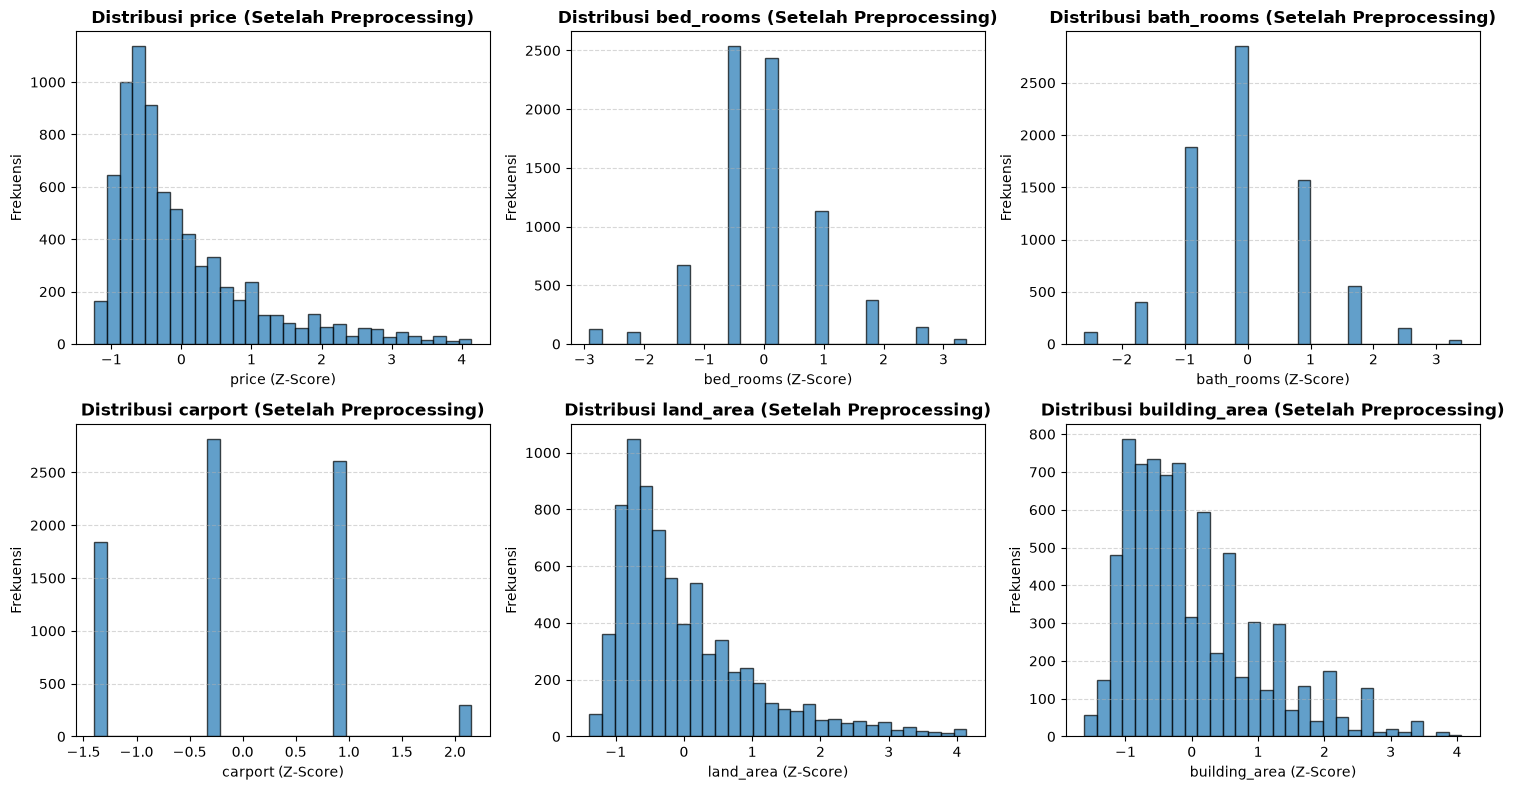

In [6]:
kolom_numerik = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_numerik):
    axes[i].hist(df_normalized[col], bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Distribusi {col} (Setelah Preprocessing)', fontweight='bold')
    axes[i].set_xlabel(f'{col} (Z-Score)')
    axes[i].set_ylabel('Frekuensi')
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### Visualisasi Boxplot Setelah Penghapusan Outlier

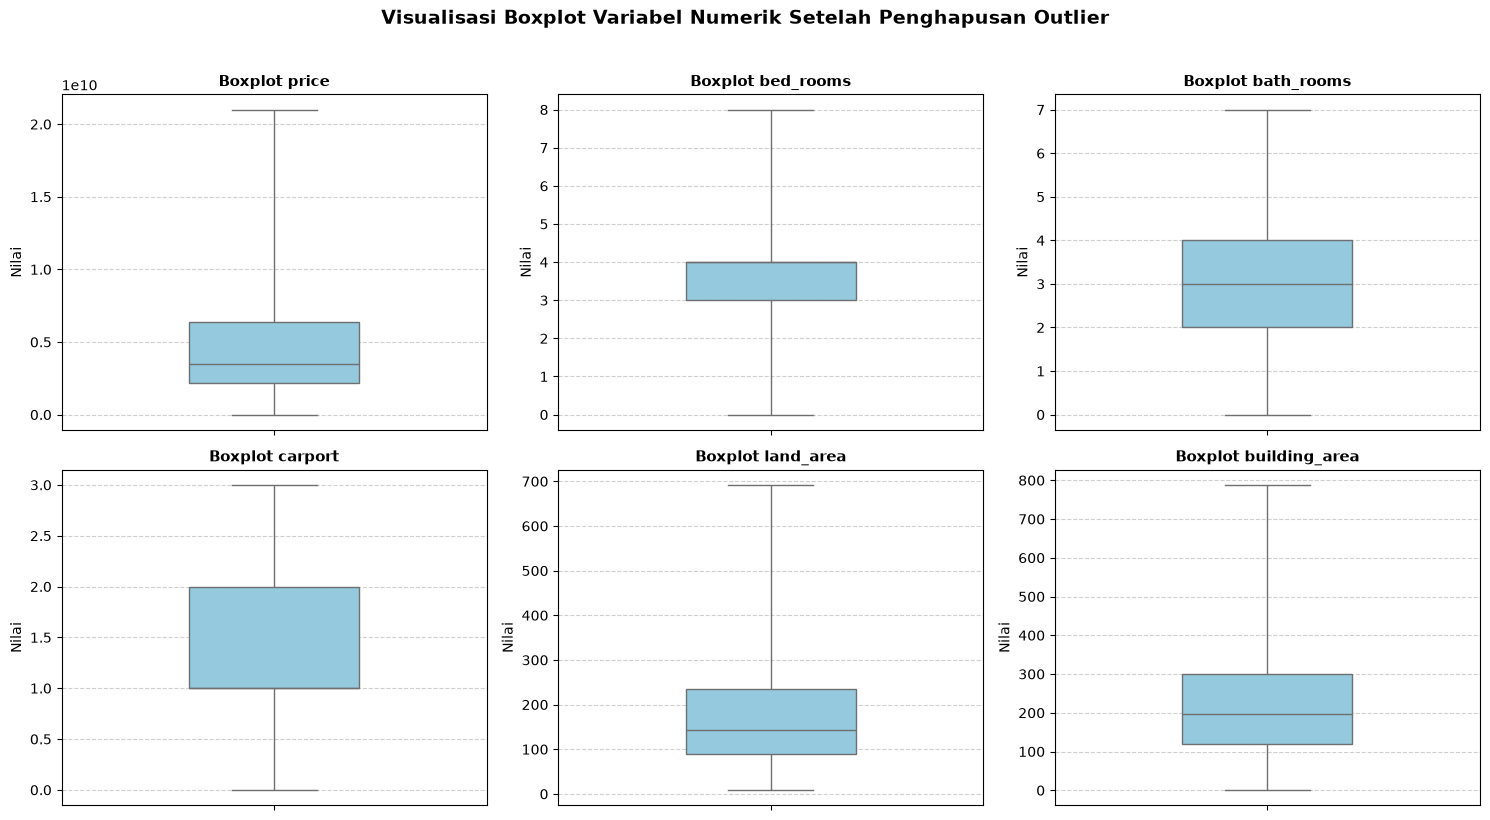

In [9]:
kolom_numerik = [
    'price',
    'bed_rooms',
    'bath_rooms',
    'carport',
    'land_area',
    'building_area'
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(kolom_numerik):
    sns.boxplot(y=df_bersih_outlier[col], ax=axes[i], color='skyblue', width=0.4, whis=(0, 100))
    axes[i].set_title(f'Boxplot {col}', fontweight='bold', fontsize=11)
    axes[i].set_ylabel('Nilai')
    axes[i].grid(axis='y', linestyle='--', alpha=0.6)

plt.suptitle('Visualisasi Boxplot Variabel Numerik Setelah Penghapusan Outlier', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Korelasi Antar Fitur Setelah Preprocessing

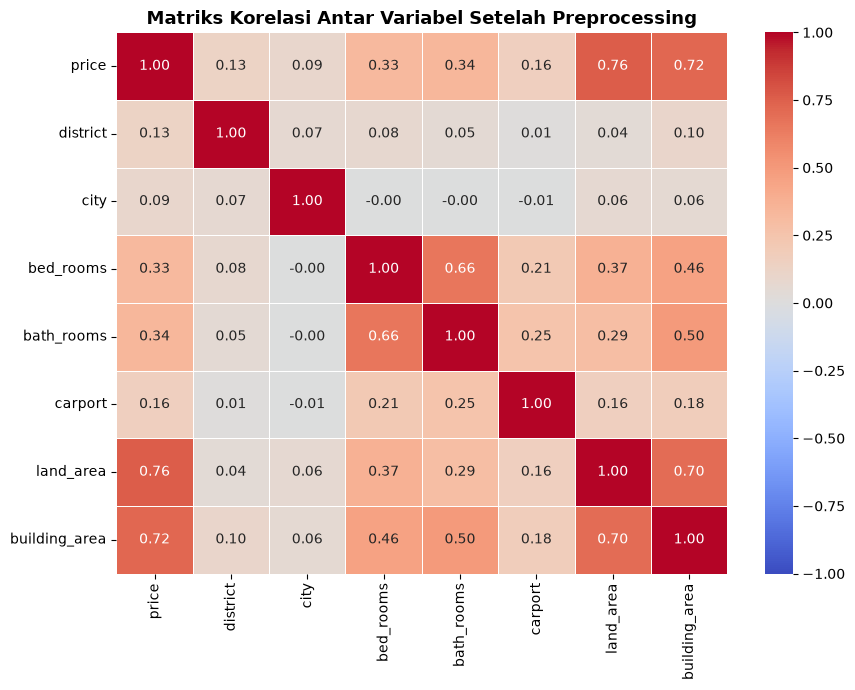

In [10]:
plt.figure(figsize=(9, 7))
korelasi = df_normalized.corr()

sns.heatmap(
    korelasi, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    linewidths=0.5, 
    vmin=-1, 
    vmax=1
)
plt.title('Matriks Korelasi Antar Variabel Setelah Preprocessing', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
corr_setelah = df_normalized.corr()

corr_setelah['price'].sort_values(ascending=False)

price           1.000
land_area       0.761
building_area   0.725
bath_rooms      0.344
bed_rooms       0.327
carport         0.160
district        0.132
city            0.090
Name: price, dtype: float64